# **CHECKPOINT 01 - PARTE 02 - Aprendizado Supervisionado: Classificação**

## Curso: ENGENHARIA DA COMPUTAÇÃO

## Disciplina:  INTELIGÊNCIA ARTIFICIAL E COMPUTACIONAL

## Turmas: 3ECA e 3ECR (1o semestre de 2024)

## Professor: André Tritiack

## Pontuação Máxima: 7.00 pontos



## INSIRA NESSA CÉLULA O NOME E O RM DOS INTEGRANTES DO GRUPO









# **Introdução**

Mas últimas duas aulas, estudamos o uso de algoritmos de **Aprendizado de Máquina Supervisionado**. Focamos nos algoritmos utilizados para **classificação**, que é a tarefa de predizer classes (rótulos categóricos) para conjuntos de dados (numéricos ou transformados em numéricos).

Além do algoritmo K-Vizinhos Mais Próximos (K-Nearest Neighbors) que estudamos, existem muitos algoritmos para se realizar essa tarefa, entre eles:

- Regressão Logística

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

- Naive Bayes

https://scikit-learn.org/stable/modules/naive_bayes.html

- Máquina de Vetor Suporte (SVM)

https://scikit-learn.org/stable/modules/svm.html#classification

- Árvore de Decisão (Decision Tree)

https://scikit-learn.org/stable/modules/tree.html

- Random Forest

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html


Cada uma dessas técnicas tem uma forte base matemática e conceitual. Os algoritmos foram propostos ao longo de diversas décadas e possuem diferentes cenários de aplicações.

Nos exercícios a seguir, você e seu grupo receberão conjuntos de dados e precisarão aplicar duas dessas técnicas em cada exercício.

--------------------------

------------------
## <font color='red'> Atenção</fonte>:

A seguir são apresentados dois datasets de pessoas reais.

Ao se trabalhar com dados de pessoas devemos considerar a origem e os preceitos **bioéticos** envolvidos em sua coleta, construção e utilização.

Além disso, é boa prática que os dados estejam anonimizados.

----------------------
# **QUESTÃO 01 (3.50 PONTOS)**

## **Diagnóstico médico: Problemas Ortopédicos na Coluna Vertebral**

Esse dataset contém dados sobre problemas ortopédicos na coluna vertebral, diagnosticados no Centre Médico-Chirurgical de Réadaptation des Massues, em Lyon, France. Contém 6 atributos biomecânicos para 310 entradas anonimizadas, sendo 100 de pacientes considerados sem problemas (Normal - NO), 60 de pacientes com Hérnia de Disco (Disk Hernia - DH) e 150 de pacientes com Espondilolistese (Spondylolisthesis - SL).

O dataset foi disponibilizado em um arquivo .csv, em anexo da tarefa.

Maiores informações disponíveis em https://www.openml.org/d/1523

## Parte 1: Importação de bibliotecas

In [129]:
import pandas as pd

# A biblioteca Seaborn nos ajudará a visualizar alguns gráficos.
import seaborn as sns

# INSIRA ABAIXO TODAS AS BIBLIOTECAS QUE UTILIZAR.
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Parte 2: Importação dos dados e Análise Exploratória

Crie um dataframe chamado "df" a partir dos dados do arquivo .csv "questao_01" anexo à tarefa.

Exemplo: df = pd.read_csv("NOME DO ARQUIVO.csv")

Escreva abaixo o seu código:

In [120]:
# Criação do dataframe
df = pd.read_csv('/content/questao_01.csv')

In [121]:
# Visualize o tamanho do dataframe
df.shape


(310, 8)

In [122]:
# Visualize os primeiros registros
df.head()

,Unnamed: 0,V1,V2,V3,V4,V5,V6,diagnostic
0,0,63.027818,22.552586,39.609117,40.475232,98.672917,-0.254400,Disk Hernia
1,1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Disk Hernia
2,2,68.832021,22.218482,50.092194,46.613539,105.985136,-3.530317,Disk Hernia
3,3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,Disk Hernia
4,4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Disk Hernia


In [123]:
# Mostre uma tabela com as informações dos atributos (formato dos dados)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  310 non-null    int64  
 1   V1          310 non-null    float64
 2   V2          310 non-null    float64
 3   V3          310 non-null    float64
 4   V4          310 non-null    float64
 5   V5          310 non-null    float64
 6   V6          310 non-null    float64
 7   diagnostic  310 non-null    object 
dtypes: float64(6), int64(1), object(1)
memory usage: 19.5+ KB


In [124]:
# Mostre uma tabela com as estatísticas descritivas dos atributos
df.describe()

,Unnamed: 0,V1,V2,V3,V4,V5,V6
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,154.500000,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,89.633513,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,0.000000,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,77.250000,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,154.500000,58.691038,16.357689,49.562398,42.404912,118.268178,11.767933
75%,231.750000,72.877696,22.120395,63.000000,52.695889,125.467675,41.287352
max,309.000000,129.834041,49.431864,125.742386,121.429566,163.071041,418.543082


In [125]:
# Exclua a coluna "Unnamed: 0"
df.drop(columns=['Unnamed: 0'], inplace=True)

Apenas execute a célula abaixo:

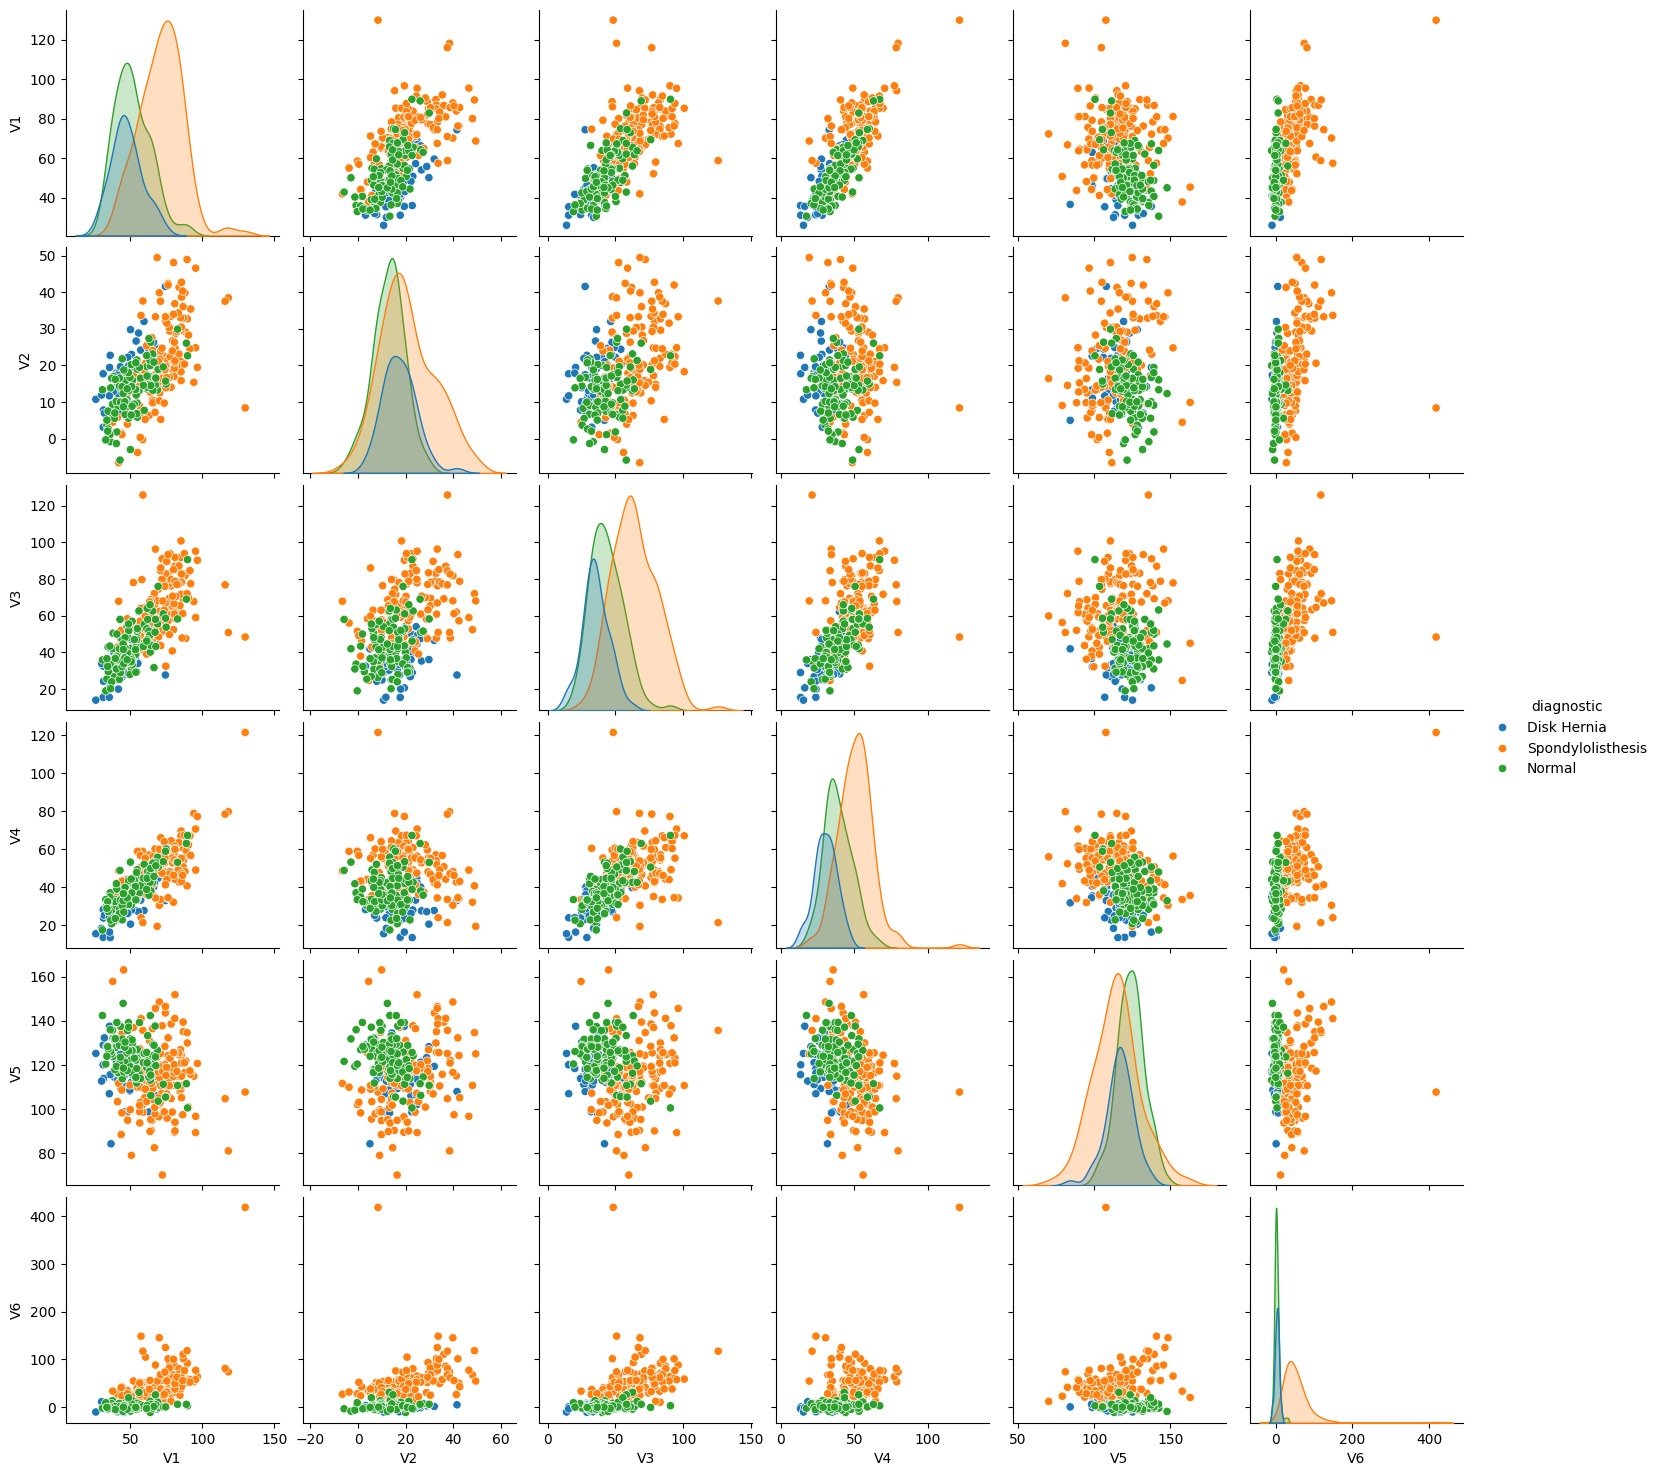

In [126]:
# Esta ação pode demorar alguns segundos.
# Você visualizará alguns gráficos de distribuição e de dispersão referentes aos atributos (V1 a V6) em relação à coluna alvo (diagnostic)
sns.pairplot(df, hue='diagnostic')

# Parte 3: Pré Processamento

Usando o LabelEncoder, converta os dados categóricos da coluna "diagnostic" em dados numéricos.

Faça as importações na Parte 1.

Escreva abaixo o seu código:


In [127]:
# Conversão de dados categóricos em numéricos (coluna "diagnostic")

label_encoder = LabelEncoder()
df['diagnostic'] = label_encoder.fit_transform(df['diagnostic'])


In [128]:
#Visualização dos dados da coluna "diagnostic" após a transformação

df['diagnostic']


0      0
1      0
2      0
3      0
4      0
      ..
305    1
306    1
307    1
308    1
309    1
Name: diagnostic, Length: 310, dtype: int64

# Parte 4: Criação dos dados de entrada (X) e dados de saída (y) e separação de dados de treinamento e teste

Crie as variáveis X e y.

X deve ser um dataframe que contenha os dados dos seis atributos referentes aos biomarcadores (V1 a V6).

y deve ser um array com os dados da coluna "diagnostic".

In [84]:
# Coloque aqui o seu código para a variável X
X = df[['V1', 'V2', 'V3', 'V4', 'V5', 'V6']]

In [85]:
# Coloque aqui o seu código para a variável y
y = df['diagnostic'].values

In [86]:
# Visualize os primeiros registros do dataframe X
print(X.head())


          V1         V2         V3         V4          V5         V6
0  63.027818  22.552586  39.609117  40.475232   98.672917  -0.254400
1  39.056951  10.060991  25.015378  28.995960  114.405425   4.564259
2  68.832021  22.218482  50.092194  46.613539  105.985136  -3.530317
3  69.297008  24.652878  44.311238  44.644130  101.868495  11.211523
4  49.712859   9.652075  28.317406  40.060784  108.168725   7.918501


In [87]:
# Visualize X como um array Numpy
X_array = X.values
print(X_array)

[[ 63.027818  22.552586  39.609117  40.475232  98.672917  -0.2544  ]
 [ 39.056951  10.060991  25.015378  28.99596  114.405425   4.564259]
 [ 68.832021  22.218482  50.092194  46.613539 105.985136  -3.530317]
 ...
 [ 61.446597  22.694968  46.170347  38.751628 125.670725  -2.70788 ]
 [ 45.252792   8.693157  41.583126  36.559635 118.545842   0.21475 ]
 [ 33.841641   5.073991  36.641233  28.767649 123.945244  -0.199249]]


In [92]:
# Visualize y como um array Numpy
y_array = y
y_array


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

Na Parte 1, importe a função train_test_split do sklearn.

Abaixo, separe 70% dos dados para treinamento e 30% para teste.

Utilize os nomes X_train, X_test, y_train e y_test


In [89]:
# Separação de dados de treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Tamanho do conjunto de teste (X_test, y_test):", X_test.shape, y_test.shape)

Tamanho do conjunto de teste (X_test, y_test): (93, 6) (93,)


In [90]:
# Visualize o tamanho de X_train
X_train.head()

,V1,V2,V3,V4,V5,V6
299,82.905351,29.894119,58.250542,53.011232,110.708958,6.079338
288,74.565015,15.724320,58.618582,58.840695,105.417304,0.599247
72,84.974132,33.021175,60.859873,51.952957,125.659534,74.333409
15,44.318907,12.537992,36.098763,31.780915,124.115836,5.415825
10,49.706610,13.040974,31.334500,36.665635,108.648265,-7.825986


In [91]:
# Visualize o tamanho de X_test
X_test.head()

,V1,V2,V3,V4,V5,V6
289,44.430701,14.174264,32.243495,30.256437,131.717613,-3.604255
9,36.686353,5.010884,41.948751,31.675469,84.241415,0.664437
57,46.855781,15.351514,38.000000,31.504267,116.250917,1.662706
60,74.377678,32.053104,78.772013,42.324573,143.560691,56.125906
25,54.124920,26.650489,35.329747,27.474432,121.447011,1.571205


In [72]:
# Visualize o tamanho de y_train
len(y_train)

217

In [73]:
# Visualize o tamanho de y_test
len(y_test)

93

# Parte 5.1: Criação do primeiro modelo, utilizando o primeiro algoritmo.

Escolha um algoritmo na lista fornecida no começo deste arquivo.

Importe o pacote referente a este algoritmo na parte 01 da atividade.

Em seguida, crie a instância do modelo, treine e gere o array com as previsões (y_predict_1)





In [94]:
# Crie a instância do primeiro modelo:
modelo01 = GaussianNB()

In [95]:
# Treine o primeiro modelo:
modelo01.fit(X_train, y_train)

GaussianNB()

In [99]:
# Gere o array de previsões "y_predict":
y_predict = modelo01.predict(X_test)


In [98]:
# Visualize y_predict_1:
y_predict

array([1, 0, 0, 2, 0, 2, 2, 2, 0, 0, 2, 2, 0, 1, 1, 0, 0, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 0, 1, 1, 2, 2, 2, 1, 2, 2, 0, 1, 2, 2, 0, 0, 2, 1,
       1, 2, 1, 1, 0, 2, 2, 1, 2, 2, 2, 1, 0, 2, 2, 0, 2, 2, 2, 2, 0, 1,
       2, 2, 2, 1, 1, 1, 2, 1, 2, 0, 0, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 1, 0, 2, 1])

# Parte 5.2: Criação do segundo modelo, utilizando o segundo algoritmo.

Escolha um segundo algoritmo na lista fornecida no começo deste arquivo.

Importe o pacote referente a este algoritmo na parte 01 da atividade.

Em seguida, crie a instância do modelo, treine e gere o array com as previsões (y_predict_2)

In [102]:
# Crie a instância do primeiro modelo:
modelo02= SVC()

In [104]:
# Treine o primeiro modelo:
modelo02.fit(X_train, y_train)

SVC()

In [107]:
# Gere o array de previsões "y_predict_2":
y_predict_2 = modelo02.predict(X_test)

In [108]:
# Visualize y_predict_2:
y_predict_2

array([1, 0, 1, 2, 0, 2, 2, 2, 1, 0, 2, 2, 1, 1, 1, 0, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 1, 1, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 2, 1, 0, 2, 1,
       1, 2, 1, 1, 1, 2, 2, 1, 2, 2, 2, 1, 0, 2, 2, 1, 2, 2, 2, 2, 1, 1,
       2, 2, 2, 1, 1, 1, 2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 1, 1, 2, 2])

# Parte 6: Avaliação dos dois modelos treinados, usando a acurácia.

Importe o pacote "accuracy_score" do sklearn na Parte 1.

Apresente strings formatadas (f-strings) com o valor da acurácia de cada modelo.



In [116]:
# Apresente a acurácia do primeiro modelo.
acuracia01 = 100 *accuracy_score(y_test, y_predict)
print(f'A acurácia do modelo será de: {acuracia01: .2f} %')

A acurácia do modelo será de:  78.49 %


In [117]:
# Apresente a acurácia do segundo modelo.
acuracia02= accuracy_score(y_test, y_predict_2)
print(f'A acurácia do modelo será de: {acuracia02: .2f} %')

A acurácia do modelo será de:  0.81 %


# Parte 7: Comentários e conclusões do grupo.

Insira nesta célula de texto as conclusões sobre a atividade desenvolvida.

----------------------
# **QUESTÃO 02 (4.50 PONTOS)**

## **Diagnóstico médico: Diabetes no povo Pima**

## Você pode construir um modelo de aprendizado de máquina para prever com precisão se os pacientes no conjunto de dados têm diabetes ou não?

Esse dataset contém dados sobre incidência de diabetes em mulheres do Povo Pima (índios nativos norte americanos originários do atual Estado do Arizona). Contém 8 atributos biomédicos para 768 entradas anonimizadas, sendo 500 testados negativo para diabetes e 268 testados positivo para diabetes.

Faça o download do dataset:

https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database


Utilize as técnicas e a mesma sequência e estrutura da questão 01 para desenvolver sua solução.

Escolha o algoritmo de sua preferência.

In [131]:
dados = pd.read_csv('/content/diabetes.csv')

In [132]:
# Visualize o tamanho do dataframe
dados.shape

(768, 9)

In [135]:
# Mostre uma tabela com as informações dos atributos (formato dos dados)
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [134]:
# Mostre uma tabela com as estatísticas descritivas dos atributos
dados.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


KeyError: 'distribuicao'

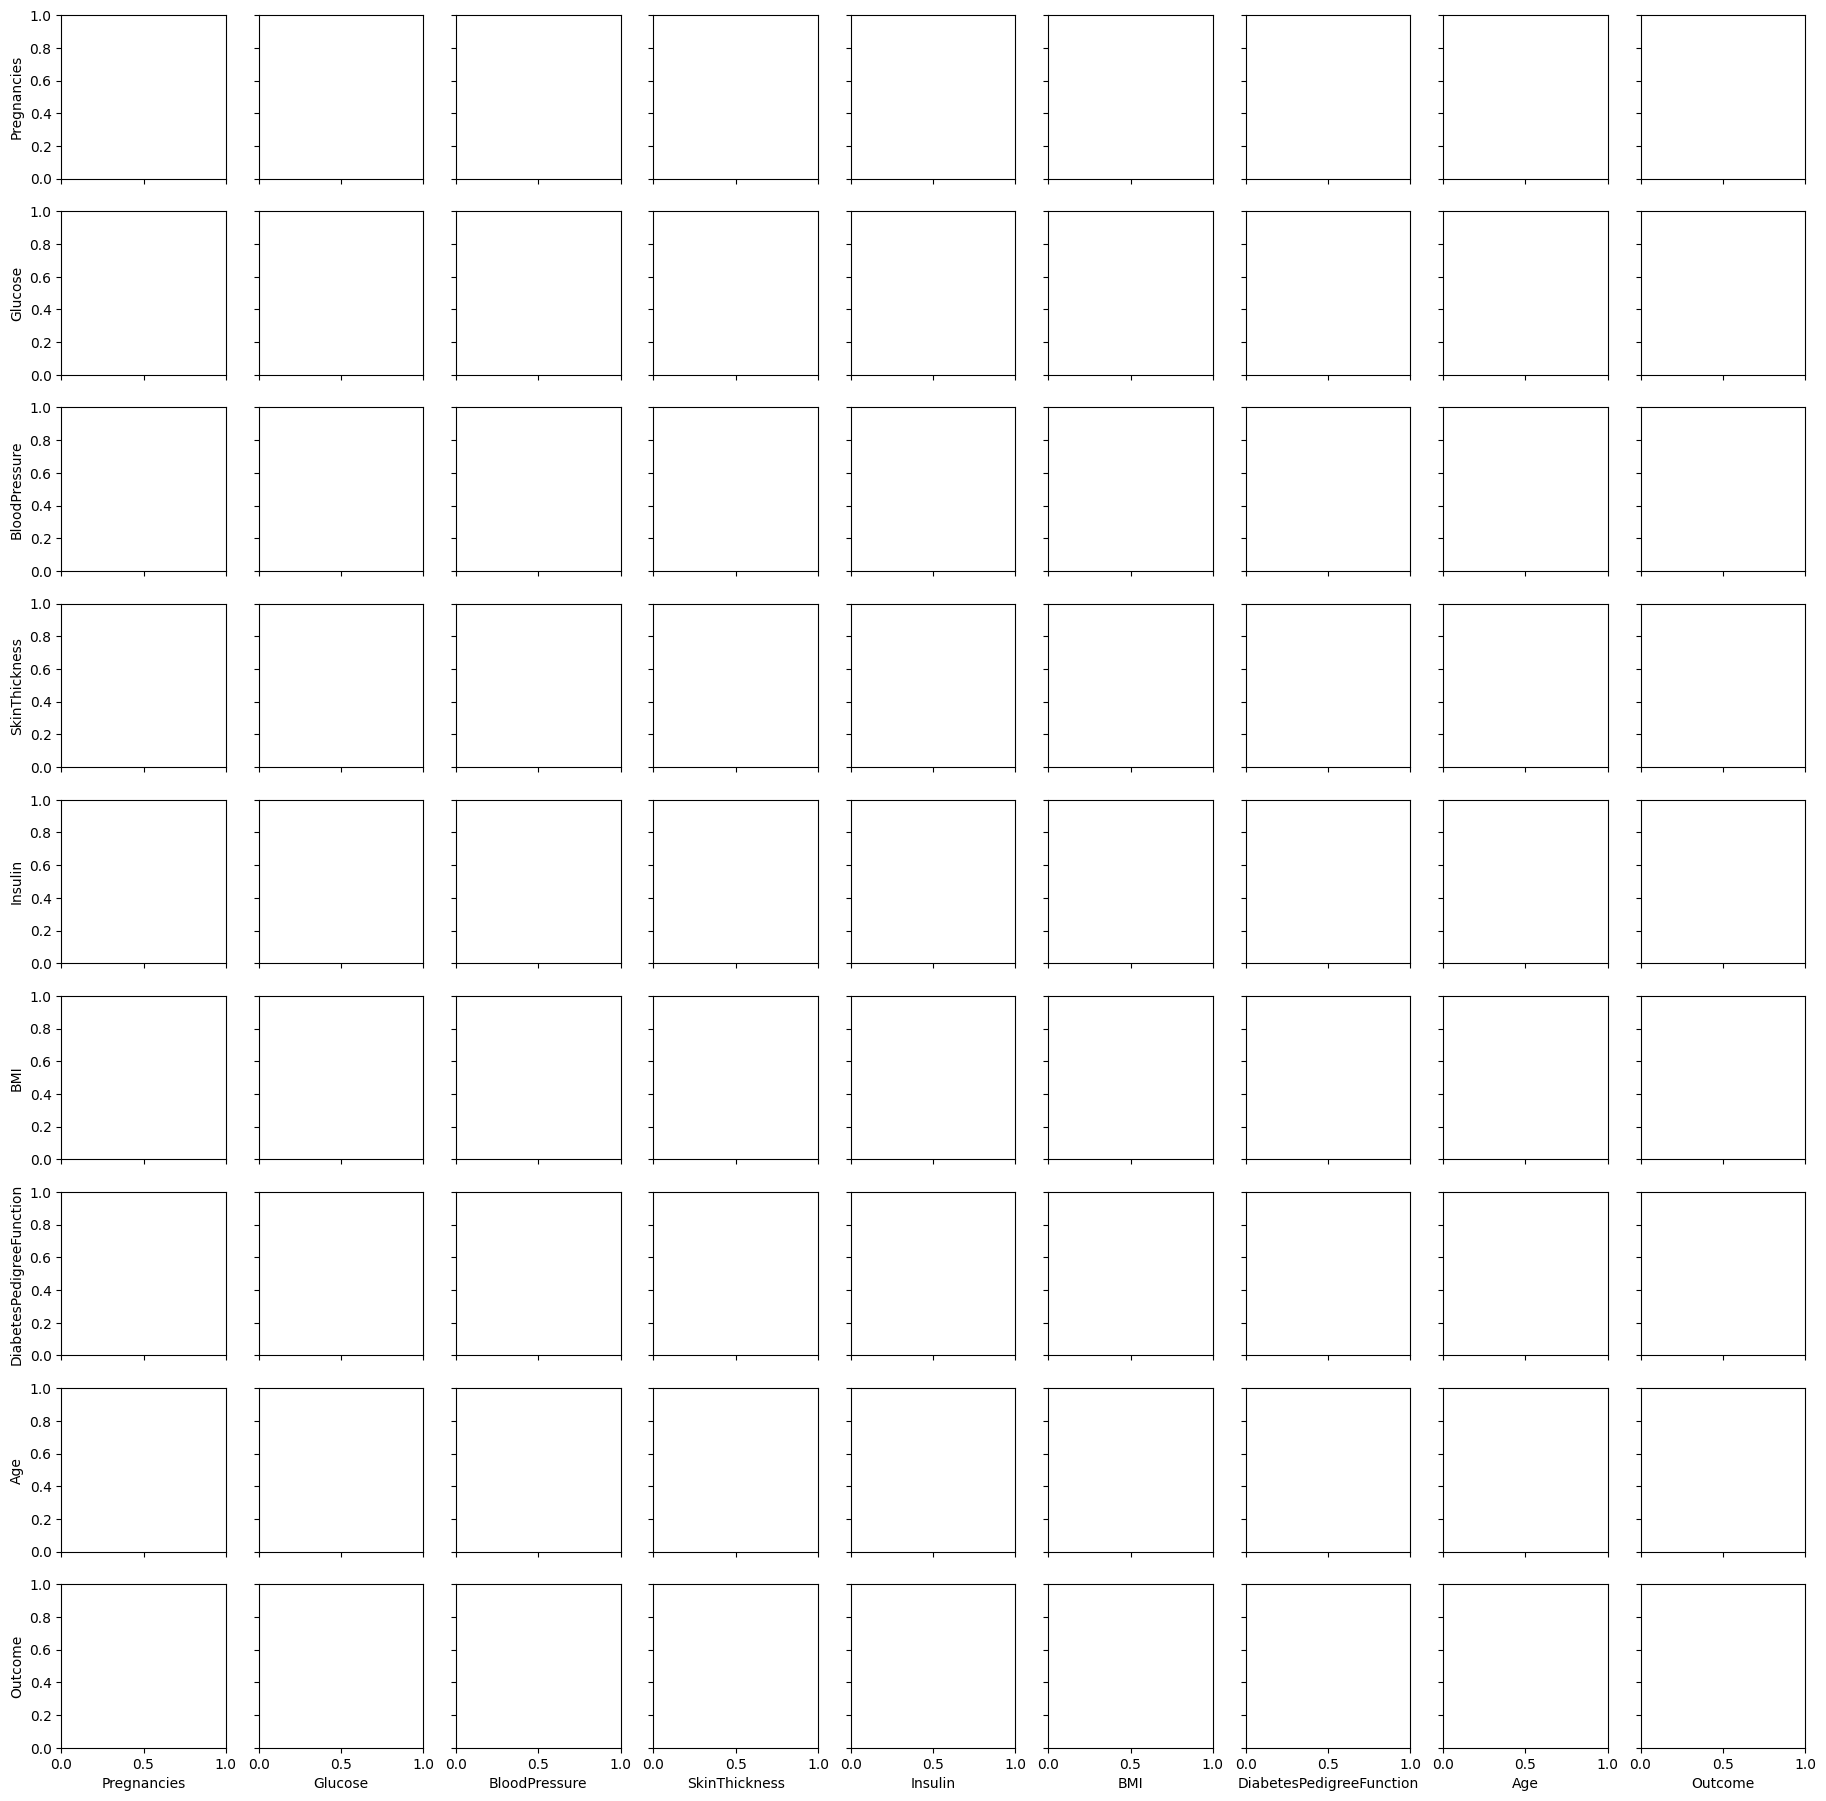

In [136]:
# Esta ação pode demorar alguns segundos.
# Você visualizará alguns gráficos de distribuição e de dispersão referentes aos atributos (V1 a V6) em relação à coluna alvo (diagnostic)
sns.pairplot(dados, hue='distribuicao')